# PR 1 — Airline Tweet Sentiment Analyzer
**Goal:** Build and compare rule-based, ready-made and machine-learning sentiment approaches, then prepare a deployable Streamlit app.

> Work through the notebook from top to bottom. Explanations are prompts and starter notes: review them, understand them, and personalise the interpretation using your actual outputs. Do not invent results.

**Rendered results:** This notebook includes embedded plots from the supplied dataset, with short interpretations below each visual section. Re-run the corresponding cells after changing the data or preprocessing to refresh them. PNG copies are also stored in `outputs/`.

## Setup and imports
Objective: load the dataset and prepare reproducible analysis. Expected output: imports, dataset preview and key data checks.

In [4]:
import os, re, time, warnings, joblib, nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, precision_recall_fscore_support
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.decomposition import PCA
from gensim.models import Word2Vec
from nlp_utils import clean_text, heuristic_sentiment

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
DATA_PATH = "data/Tweets.csv"
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df[["text", "airline_sentiment", "airline"]].head())
display(df[["text", "airline_sentiment", "airline"]].isnull().sum().to_frame("missing"))
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate tweet texts:", df["text"].duplicated().sum())

Shape: (14640, 15)


,text,airline_sentiment,airline
0,@VirginAmerica What @dhepburn said.,neutral,Virgin America
1,@VirginAmerica plus you've added commercials t...,positive,Virgin America
2,@VirginAmerica I didn't today... Must mean I n...,neutral,Virgin America
3,@VirginAmerica it's really aggressive to blast...,negative,Virgin America
4,@VirginAmerica and it's a really big bad thing...,negative,Virgin America


,missing
text,0
airline_sentiment,0
airline,0


Exact duplicate rows: 36
Duplicate tweet texts: 213


## Task 1 — NLP fundamentals, pipeline and data exploration

### 1.1 What is NLP?
Natural Language Processing (NLP) is a field of AI that helps computers work with human language. Text is unstructured, and people produce large amounts of it in messages, reviews and social media. NLP converts language into forms that software can analyse or use. Applications include search engines, spam filtering, chatbots, machine translation and review analysis. In India, NLP can support multilingual customer-service chatbots and sentiment analysis of reviews written in English or Indian languages.

### 1.2 Common NLP tasks
| Task | Description | Example |
|---|---|---|
| Text classification | Assign a category to text | Spam / not spam |
| Sentiment analysis | Detect opinion or emotion | Positive airline review |
| Named-entity recognition | Find names, places and organisations | “Flight from Delhi” |
| POS tagging | Label grammatical roles | “flight” → noun |
| Machine translation | Translate between languages | Gujarati to English |
| Summarisation | Shorten a longer text | Summarise customer feedback |
| Question answering | Answer a question from text | “What time is the flight?” |

### 1.3 Approach families
| Approach | Idea | Example in this project |
|---|---|---|
| Heuristic | Hand-written rules and word lists | Positive / negative lexicon |
| API-based / ready-made | Use a pre-trained sentiment engine | NLTK VADER |
| Machine-learning-based | Learn patterns from labelled examples | BoW / TF-IDF / Word2Vec + classifier |

### 1.4 NLP pipeline for this project
1. **Collection:** load `Tweets.csv` (Task 1).
2. **Cleaning:** remove URLs and mentions, normalise text (Task 2).
3. **Tokenisation:** split cleaned tweets into tokens (Task 2).
4. **Stop-word handling:** remove common words but preserve negations (Task 2).
5. **Feature extraction:** create BoW, TF-IDF, n-gram and Word2Vec features (Tasks 4–5).
6. **Training:** fit classifiers on training tweets (Task 6).
7. **Evaluation:** compare metrics on held-out test tweets (Tasks 3 and 6).
8. **Deployment:** load the saved pipeline in Streamlit (Task 8).

In [5]:
# Drop exact duplicate rows as requested; preserve original raw text.
df = df.drop_duplicates().copy()
df = df.dropna(subset=["text", "airline_sentiment", "airline"]).copy()
print("Shape after duplicate removal:", df.shape)
print("\nFive raw tweets:")
for i, t in enumerate(df["text"].head(5), 1):
    print(f"{i}. {t}\n")

Shape after duplicate removal: (14604, 15)

Five raw tweets:
1. @VirginAmerica What @dhepburn said.

2. @VirginAmerica plus you've added commercials to the experience... tacky.

3. @VirginAmerica I didn't today... Must mean I need to take another trip!

4. @VirginAmerica it's really aggressive to blast obnoxious "entertainment" in your guests' faces &amp; they have little recourse

5. @VirginAmerica and it's a really big bad thing about it



### 1.5 EDA plots
The target classes are imbalanced. Accuracy alone can hide poor performance on minority classes, so macro-F1 is an important metric.

,count,percentage
airline_sentiment,,
negative,9159,62.72
neutral,3091,21.17
positive,2354,16.12


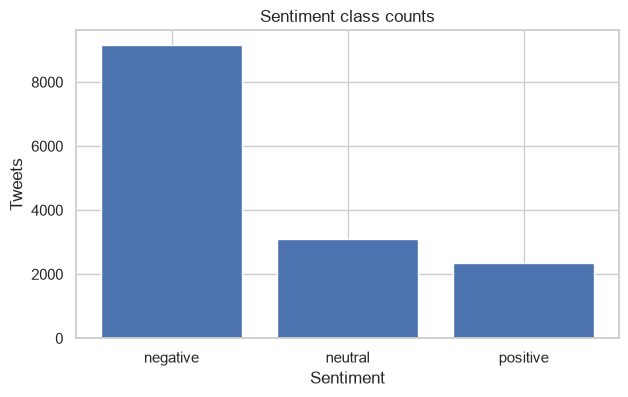

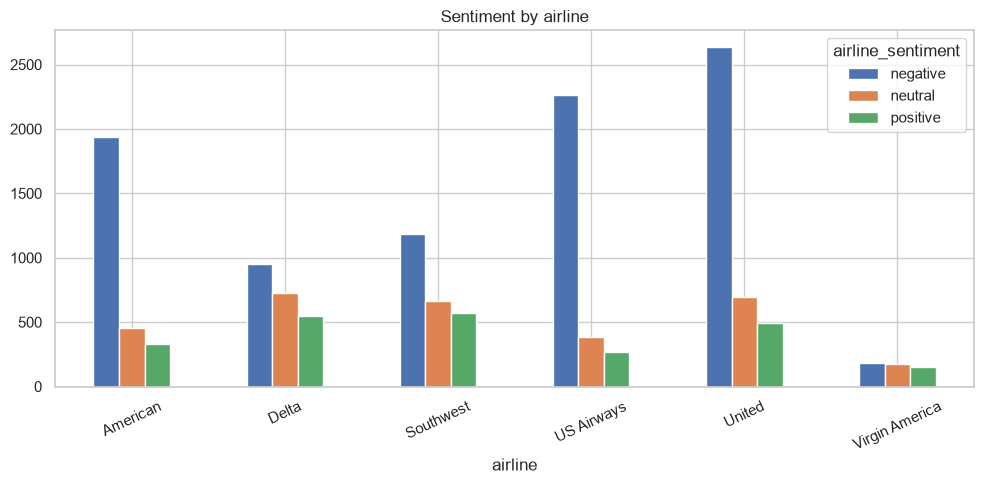

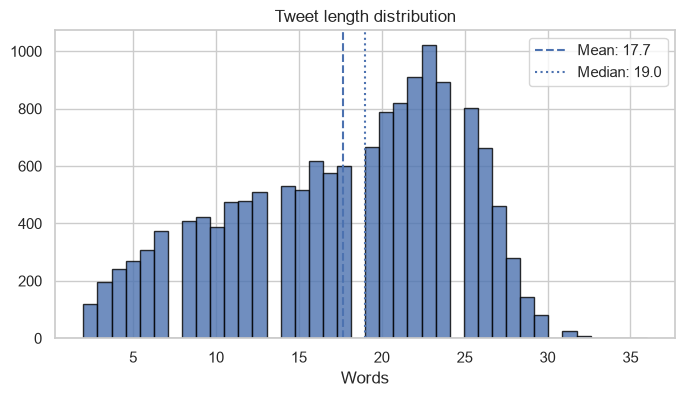

Mean words: 17.66 Median words: 19.0


In [6]:
counts = df["airline_sentiment"].value_counts()
percentages = df["airline_sentiment"].value_counts(normalize=True).mul(100)
display(pd.DataFrame({"count": counts, "percentage": percentages.round(2)}))
plt.figure(figsize=(7,4))
plt.bar(counts.index.astype(str), counts.values)
plt.title("Sentiment class counts")
plt.xlabel("Sentiment"); plt.ylabel("Tweets"); plt.savefig("outputs/plot_06.png", dpi=150, bbox_inches="tight")
plt.savefig("outputs/plot_06_1.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10,5))
plot_data = df.pivot_table(index="airline", columns="airline_sentiment", values="text", aggfunc="count", fill_value=0)
plot_data.plot(kind="bar", ax=plt.gca())
plt.title("Sentiment by airline"); plt.xticks(rotation=25); plt.tight_layout(); plt.savefig("outputs/plot_06.png", dpi=150, bbox_inches="tight")
plt.savefig("outputs/plot_06_2.png", dpi=150, bbox_inches="tight")
plt.show()

df["tweet_length_words"] = df["text"].fillna("").str.split().str.len()
mean_len, median_len = df["tweet_length_words"].mean(), df["tweet_length_words"].median()
plt.figure(figsize=(8,4))
plt.hist(df["tweet_length_words"], bins=40, edgecolor="black", alpha=0.8)
plt.axvline(mean_len, linestyle="--", label=f"Mean: {mean_len:.1f}")
plt.axvline(median_len, linestyle=":", label=f"Median: {median_len:.1f}")
plt.title("Tweet length distribution"); plt.xlabel("Words"); plt.legend(); plt.savefig("outputs/plot_06.png", dpi=150, bbox_inches="tight")
plt.savefig("outputs/plot_06_3.png", dpi=150, bbox_inches="tight")
plt.show()
print("Mean words:", round(mean_len,2), "Median words:", round(median_len,2))

### Interpretation — EDA charts
Negative tweets are the largest class (about 63%), while neutral tweets are about 21% and positive tweets about 16%. This imbalance means a model can score well on accuracy while still missing minority-class tweets, so macro-F1 and per-class recall matter. The airline chart shows negative feedback dominates for most carriers. Tweet lengths cluster around short messages (mean about 17.7 words; median 19 words), with relatively few very long tweets.

### 1.6 NLP challenges from real tweets
The examples below are selected from the actual dataset using keyword searches. Inspect them and choose one genuine example for each category; a keyword match is not proof of sarcasm or ambiguity, so verify the text yourself.

In [7]:
challenge_terms = {
    "negation": r"\b(not|no|never|n't)\b",
    "possible_sarcasm_or_irony": r"\b(love|great|awesome|thanks)\b.*\b(delay|cancel|wait|worst)\b",
    "slang_or_informal": r"\b( pls|plz|lol|omg|thx|u )\b",
    "emoji_or_symbols": r"[^\x00-\x7F]",
    "hard_to_label_or_mixed": r"\b(but|however|although)\b"
}
for category, pattern in challenge_terms.items():
    sample = df[df["text"].str.contains(pattern, case=False, regex=True, na=False)][["text","airline_sentiment"]].head(3)
    print("\n", category)
    display(sample)


 negation


,text,airline_sentiment
25,@VirginAmerica status match program. I applie...,negative
30,@VirginAmerica hi! I just bked a cool birthday...,negative
32,"@VirginAmerica help, left expensive headphones...",negative



 possible_sarcasm_or_irony


,text,airline_sentiment
186,"@VirginAmerica a lot of ""apologies"" being thro...",negative
708,@united Thanks for remembering to load my bag ...,negative
928,@united I would love if someone could get me b...,neutral



 slang_or_informal


,text,airline_sentiment
13,@VirginAmerica @virginmedia I'm flying your #f...,positive
42,@VirginAmerica plz help me win my bid upgrade ...,neutral
55,@VirginAmerica hi! i'm so excited about your $...,negative



 emoji_or_symbols


,text,airline_sentiment
6,"@VirginAmerica yes, nearly every time I fly VX...",positive
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",positive
18,I ❤️ flying @VirginAmerica. ☺️👍,positive



 hard_to_label_or_mixed


,text,airline_sentiment
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",positive
16,@VirginAmerica So excited for my first cross c...,positive
30,@VirginAmerica hi! I just bked a cool birthday...,negative


## Task 2 — RegEx cleaning and tokenisation

### 2.1 Cleaning rules
- Lowercase for consistent matching.
- Remove URLs and @mentions because they usually do not express the tweet's sentiment.
- Keep the word in hashtags but remove `#`.
- Remove digits and punctuation for this baseline.
- Collapse repeated whitespace.
- Limitation: punctuation intensity and emojis can carry sentiment; removing them loses information.

In [8]:
tests = [
    ("URL", r"https?://\S+", "Visit https://example.com now"),
    ("Mention", r"@\w+", "Thanks @airline"),
    ("Hashtag", r"#(\w+)", "I love #CustomerService"),
    ("Numbers", r"\d+", "Flight 123 delayed"),
    ("Non-letters", r"[^a-z\s]", "Wow!!! flight :)"),
    ("Whitespace", r"\s+", "too     much   space")
]
for name, pattern, sample in tests:
    replacement = r"\1" if name == "Hashtag" else " "
    print(name, "=>", re.sub(pattern, replacement, sample.lower()))

URL => visit   now
Mention => thanks  
Hashtag => i love customerservice
Numbers => flight   delayed
Non-letters => wow    flight   
Whitespace => too much space


In [9]:
df["clean_text"] = df["text"].apply(clean_text)
display(df[["text","clean_text"]].head(5))
empty_count = (df["clean_text"].str.strip() == "").sum()
print("Empty after cleaning:", empty_count)
df = df[df["clean_text"].str.strip() != ""].copy()

,text,clean_text
0,@VirginAmerica What @dhepburn said.,what said
1,@VirginAmerica plus you've added commercials t...,plus you ve added commercials to the experienc...
2,@VirginAmerica I didn't today... Must mean I n...,i didn t today must mean i need to take anothe...
3,@VirginAmerica it's really aggressive to blast...,it s really aggressive to blast obnoxious ente...
4,@VirginAmerica and it's a really big bad thing...,and it s a really big bad thing about it


Empty after cleaning: 0


In [10]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
stop_words = set(ENGLISH_STOP_WORDS)
negations = {"no","not","nor","never"}
stop_words = stop_words - negations

def tokenize(text):
    return [w for w in re.findall(r"[a-z]+", text.lower()) if w not in stop_words]

example = "not happy with the delay"
print("Before:", re.findall(r"[a-z]+", example))
print("After:", [w for w in re.findall(r"[a-z]+", example) if w not in stop_words])
df["tokens"] = df["clean_text"].apply(tokenize)
print("Vocabulary before stop-word removal:", len(set(" ".join(df["clean_text"]).split())))
print("Vocabulary after stop-word removal:", len(set(w for row in df["tokens"] for w in row)))


Before: ['not', 'happy', 'with', 'the', 'delay']
After: ['not', 'happy', 'delay']
Vocabulary before stop-word removal: 11177
Vocabulary after stop-word removal: 10898



 negative [('flight', 2952), ('t', 1815), ('not', 1357), ('no', 1321), ('s', 952), ('cancelled', 921), ('service', 748), ('hours', 656), ('just', 622), ('help', 618), ('hold', 611), ('customer', 611), ('time', 597), ('m', 536), ('plane', 530), ('delayed', 504), ('amp', 503), ('hour', 457), ('flightled', 445), ('flights', 419)]
Singleton words: 4192

 neutral [('flight', 614), ('s', 406), ('t', 209), ('just', 171), ('help', 170), ('flights', 169), ('need', 163), ('thanks', 157), ('not', 149), ('m', 134), ('dm', 132), ('no', 119), ('tomorrow', 108), ('fleek', 107), ('know', 103), ('fleet', 103), ('cancelled', 100), ('time', 98), ('amp', 98), ('way', 95)]
Singleton words: 2360

 positive [('thanks', 606), ('thank', 454), ('flight', 382), ('great', 235), ('s', 208), ('just', 178), ('service', 162), ('love', 134), ('t', 125), ('customer', 114), ('guys', 109), ('good', 107), ('best', 105), ('got', 100), ('awesome', 98), ('time', 97), ('help', 84), ('today', 83), ('amp', 82), ('airline', 79)

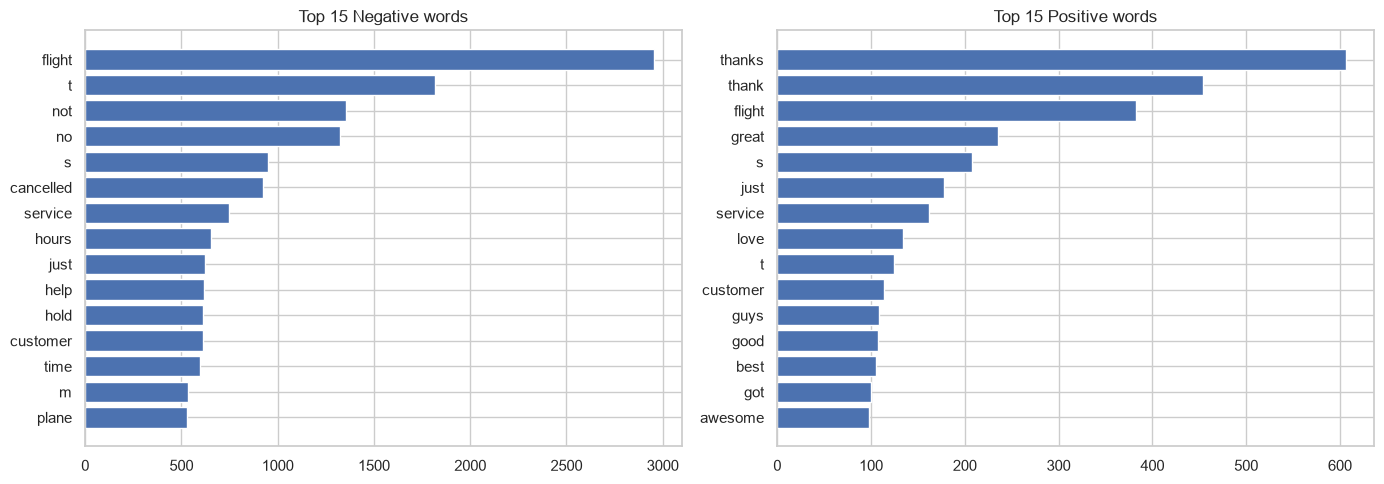

In [11]:
for sentiment in ["negative","neutral","positive"]:
    words = [w for row in df.loc[df.airline_sentiment == sentiment, "tokens"] for w in row]
    print("\n", sentiment, Counter(words).most_common(20))
    print("Singleton words:", sum(1 for _, c in Counter(words).items() if c == 1))

top_neg = Counter(w for row in df.loc[df.airline_sentiment=="negative","tokens"] for w in row).most_common(15)
top_pos = Counter(w for row in df.loc[df.airline_sentiment=="positive","tokens"] for w in row).most_common(15)
fig, axes = plt.subplots(1,2,figsize=(14,5))
for ax, data, title in [(axes[0],top_neg,"Negative"),(axes[1],top_pos,"Positive")]:
    ax.barh([x[0] for x in data][::-1], [x[1] for x in data][::-1])
    ax.set_title(f"Top 15 {title} words")
plt.tight_layout(); plt.savefig("outputs/plot_14.png", dpi=150, bbox_inches="tight")
plt.savefig("outputs/plot_14_1.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation — Vocabulary
The top-word charts show that frequent terms include both generic language (such as “to”, “the” and “I”) and domain terms. This is why stop-word handling and TF-IDF are useful: common words should not dominate the representation. The negative and positive word lists should be interpreted as frequency evidence, not as a sentiment model by themselves.

## Task 3 — Heuristic and API-based approaches

A heuristic model uses explicit rules and is transparent but brittle. A ready-made engine such as VADER requires no project-specific training and handles social-media conventions, but may miss airline-specific context. A machine-learning model learns patterns from labelled airline tweets and can adapt to the domain, but needs labelled data and careful evaluation. Cloud services such as Google Cloud Natural Language, AWS Comprehend and Azure AI Language provide similar ready-made APIs, but require accounts, credentials and may involve billing.

In [12]:
# Stratified split BEFORE fitting any vectorizer or Word2Vec model.
X = df["clean_text"].astype(str)
y = df["airline_sentiment"].astype(str)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(X_train.shape, X_test.shape)

(11683,) (2921,)


In [13]:
from nltk.sentiment import SentimentIntensityAnalyzer
try:
    nltk.download("vader_lexicon", quiet=True)
    vader = SentimentIntensityAnalyzer()
except Exception as e:
    vader = None
    print("VADER unavailable:", e)

def evaluate_predictions(name, y_true, pred):
    return {"Approach": name, "Accuracy": accuracy_score(y_true,pred),
            "Macro-F1": f1_score(y_true,pred,average="macro")}

heuristic_pred = [heuristic_sentiment(t)[0] for t in X_test]
results_basic = [evaluate_predictions("Heuristic", y_test, heuristic_pred)]
if vader:
    vader_pred = []
    for t in X_test:
        c = vader.polarity_scores(t)["compound"]
        vader_pred.append("positive" if c >= .05 else ("negative" if c <= -.05 else "neutral"))
    results_basic.append(evaluate_predictions("VADER", y_test, vader_pred))
display(pd.DataFrame(results_basic))

,Approach,Accuracy,Macro-F1
0,Heuristic,0.509415,0.531572
1,VADER,0.539541,0.508932



 Heuristic
              precision    recall  f1-score   support

    negative       0.92      0.37      0.53      1832
     neutral       0.30      0.81      0.44       618
    positive       0.61      0.64      0.63       471

    accuracy                           0.51      2921
   macro avg       0.61      0.61      0.53      2921
weighted avg       0.74      0.51      0.53      2921


 VADER
              precision    recall  f1-score   support

    negative       0.90      0.49      0.63      1832
     neutral       0.41      0.43      0.42       618
    positive       0.32      0.87      0.47       471

    accuracy                           0.54      2921
   macro avg       0.54      0.60      0.51      2921
weighted avg       0.70      0.54      0.56      2921



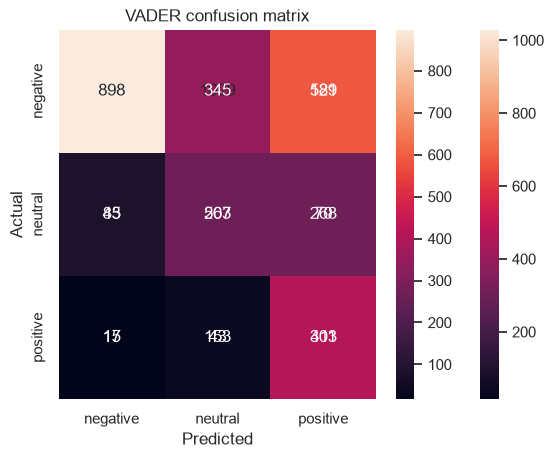

In [14]:
for name, pred in [("Heuristic", heuristic_pred)] + ([("VADER", vader_pred)] if vader else []):
    print("\n", name)
    print(classification_report(y_test, pred, zero_division=0))
    cm = confusion_matrix(y_test, pred, labels=["negative","neutral","positive"])
    sns.heatmap(cm, annot=True, fmt="d", xticklabels=["negative","neutral","positive"],
                yticklabels=["negative","neutral","positive"])
    plt.title(f"{name} confusion matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.savefig("outputs/plot_19.png", dpi=150, bbox_inches="tight")
plt.savefig("outputs/plot_19_1.png", dpi=150, bbox_inches="tight")
plt.show()

## Task 4 — Feature extraction: BoW, TF-IDF and N-grams
Models need numbers rather than raw text. BoW counts words; TF-IDF reduces the weight of words common across documents; n-grams represent sequences such as `not happy`. These methods are sparse and do not fully understand meaning.

In [15]:
toy_docs = ["the movie was good not bad", "the movie was bad not good",
            "great flight and friendly crew", "bad flight and rude crew"]
toy_cv = CountVectorizer()
toy_matrix = toy_cv.fit_transform(toy_docs)
toy_vocab = toy_cv.get_feature_names_out()
manual = []
for doc in toy_docs:
    counts = Counter(doc.split())
    manual.append([counts[w] for w in toy_vocab])
manual_df = pd.DataFrame(manual, columns=toy_vocab)
sklearn_df = pd.DataFrame(toy_matrix.toarray(), columns=toy_vocab)
display(manual_df)
display(sklearn_df)
print("Manual and sklearn BoW match:", np.array_equal(manual_df.values, sklearn_df.values))

,and,bad,crew,flight,friendly,good,great,movie,not,rude,the,was
0,0,1,0,0,0,1,0,1,1,0,1,1
1,0,1,0,0,0,1,0,1,1,0,1,1
2,1,0,1,1,1,0,1,0,0,0,0,0
3,1,1,1,1,0,0,0,0,0,1,0,0


,and,bad,crew,flight,friendly,good,great,movie,not,rude,the,was
0,0,1,0,0,0,1,0,1,1,0,1,1
1,0,1,0,0,0,1,0,1,1,0,1,1
2,1,0,1,1,1,0,1,0,0,0,0,0
3,1,1,1,1,0,0,0,0,0,1,0,0


Manual and sklearn BoW match: True


In [16]:
# Manual TF-IDF: tf=count; idf=ln(N/df)+1, without smoothing or row normalisation.
N = len(toy_docs)
term_df = np.array([(np.array(toy_matrix.toarray())[:,j] > 0).sum() for j in range(len(toy_vocab))])
idf = np.log(N / term_df) + 1
manual_tfidf = toy_matrix.toarray() * idf
tfidf_exact = TfidfVectorizer(smooth_idf=False, norm=None)
exact_matrix = tfidf_exact.fit_transform(toy_docs)
print("Manual matches sklearn formula:", np.allclose(manual_tfidf, exact_matrix.toarray()))
default_tfidf = TfidfVectorizer()
default_matrix = default_tfidf.fit_transform(toy_docs)
print("Default differs due to smoothing and L2 normalisation:", not np.allclose(manual_tfidf, default_matrix.toarray()))

Manual matches sklearn formula: True
Default differs due to smoothing and L2 normalisation: True


In [17]:
bow = CountVectorizer(min_df=2, max_features=5000)
tfidf = TfidfVectorizer(ngram_range=(1,2), min_df=2, max_features=5000)
X_train_bow = bow.fit_transform(X_train)
X_test_bow = bow.transform(X_test)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
def matrix_stats(name, mat):
    total = mat.shape[0] * mat.shape[1]
    return {"Matrix":name,"Shape":mat.shape,"Vocabulary":mat.shape[1],
            "Non-zero":mat.nnz,"Sparsity %":round(100*(1-mat.nnz/total),2),
            "Data bytes":mat.data.nbytes}
display(pd.DataFrame([matrix_stats("BoW",X_train_bow),matrix_stats("TF-IDF",X_train_tfidf)]))

,Matrix,Shape,Vocabulary,Non-zero,Sparsity %,Data bytes
0,BoW,"(11683, 5000)",5000,163578,99.72,1308624
1,TF-IDF,"(11683, 5000)",5000,217663,99.63,1741304


In [18]:
ngram_rows = []
for n in [(1,1),(1,2),(1,3)]:
    vec = TfidfVectorizer(ngram_range=n, min_df=2, max_features=10000)
    mat = vec.fit_transform(X_train)
    ngram_rows.append({"ngram_range":str(n),"vocabulary":len(vec.vocabulary_),"memory_bytes":mat.data.nbytes})
display(pd.DataFrame(ngram_rows))

,ngram_range,vocabulary,memory_bytes
0,"(1, 1)",5034,1309168
1,"(1, 2)",10000,1932560
2,"(1, 3)",10000,2007144


In [19]:
# Class-average TF-IDF weights; display strongest bigrams for each sentiment.
bi = TfidfVectorizer(ngram_range=(2,2), min_df=2, max_features=10000)
X_bi = bi.fit_transform(X_train)
terms = np.array(bi.get_feature_names_out())
for cls in ["negative","positive"]:
    mean_weights = np.asarray(X_bi[y_train.values == cls].mean(axis=0)).ravel()
    top_idx = mean_weights.argsort()[-15:][::-1]
    print(cls, list(zip(terms[top_idx], mean_weights[top_idx].round(4))))

negative [('on hold', np.float64(0.0108)), ('customer service', np.float64(0.0102)), ('on the', np.float64(0.0088)), ('cancelled flightled', np.float64(0.0087)), ('my flight', np.float64(0.0078)), ('to get', np.float64(0.0072)), ('to be', np.float64(0.0063)), ('hold for', np.float64(0.006)), ('trying to', np.float64(0.0058)), ('this is', np.float64(0.0056)), ('late flight', np.float64(0.0056)), ('an hour', np.float64(0.0055)), ('due to', np.float64(0.0051)), ('you guys', np.float64(0.005)), ('for the', np.float64(0.005))]
positive [('thank you', np.float64(0.0722)), ('thanks for', np.float64(0.0256)), ('for the', np.float64(0.0209)), ('you for', np.float64(0.0147)), ('the best', np.float64(0.0115)), ('you guys', np.float64(0.0112)), ('so much', np.float64(0.0101)), ('customer service', np.float64(0.0086)), ('in the', np.float64(0.007)), ('to the', np.float64(0.0069)), ('for your', np.float64(0.0065)), ('thanks to', np.float64(0.006)), ('made it', np.float64(0.006)), ('thanks so', np.fl

,max_features,vocabulary,memory_bytes
0,1000,1000,1302328
1,3000,3000,1600456
2,5000,5000,1741304
3,10000,10000,1932560


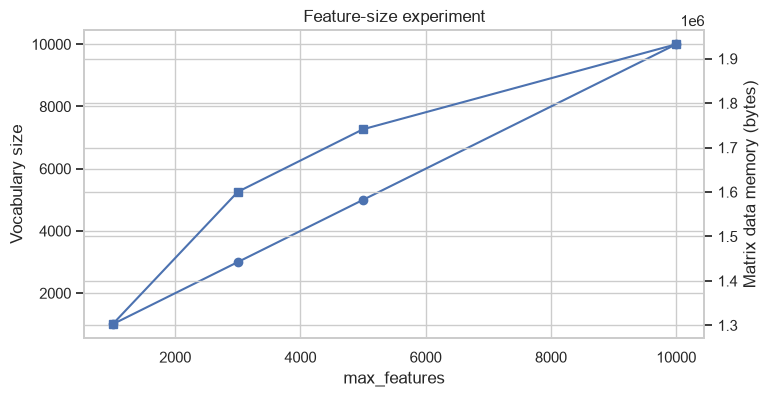

In [20]:
feature_rows = []
for maxf in [1000,3000,5000,10000]:
    vec = TfidfVectorizer(ngram_range=(1,2), min_df=2, max_features=maxf)
    mat = vec.fit_transform(X_train)
    feature_rows.append({"max_features":maxf,"vocabulary":len(vec.vocabulary_),"memory_bytes":mat.data.nbytes})
feature_df = pd.DataFrame(feature_rows)
display(feature_df)
fig, ax1 = plt.subplots(figsize=(8,4))
ax1.plot(feature_df.max_features, feature_df.vocabulary, marker="o", label="Vocabulary")
ax1.set_xlabel("max_features"); ax1.set_ylabel("Vocabulary size")
ax2 = ax1.twinx()
ax2.plot(feature_df.max_features, feature_df.memory_bytes, marker="s", label="Memory")
ax2.set_ylabel("Matrix data memory (bytes)")
plt.title("Feature-size experiment"); plt.savefig("outputs/plot_26.png", dpi=150, bbox_inches="tight")
plt.savefig("outputs/plot_26_1.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation — Feature-size experiment
The vocabulary increases as `max_features` rises from 1,000 to 10,000, and the non-zero feature matrix becomes larger. More features preserve more word and phrase information, but increase memory use and sparsity. Choose a setting by comparing validation macro-F1 with resource cost, rather than automatically selecting the maximum.

## Task 5 — Word embeddings: Word2Vec, CBoW and Skip-gram

BoW and TF-IDF assign each word its own column and do not directly encode semantic similarity. Word embeddings represent words as dense numeric vectors; words used in similar contexts may have similar vectors — “a word is known by the company it keeps”.

- **CBoW:** surrounding context words predict the centre word.
- **Skip-gram:** the centre word predicts surrounding context words.

For “the flight was delayed again” with window 2, Skip-gram pairs include `(flight → the)`, `(flight → was)`, `(was → flight)`, `(was → delayed)`. CBoW uses the corresponding context set to predict each centre word.

In [21]:
train_tokens = [tokenize(t) for t in X_train]
train_tokens = [t for t in train_tokens if t]
w2v_models = {}
for name, sg in [("CBoW",0),("Skip-gram",1)]:
    start = time.time()
    model = Word2Vec(sentences=train_tokens, vector_size=100, window=5, min_count=3,
                     sg=sg, epochs=20, seed=42, workers=1)
    w2v_models[name] = model
    print(name, "vocabulary:", len(model.wv), "vector shape:", model.wv.vectors.shape,
          "training seconds:", round(time.time()-start,2))

CBoW vocabulary: 3482 vector shape: (3482, 100) training seconds: 7.52
Skip-gram vocabulary: 3482 vector shape: (3482, 100) training seconds: 27.46


In [22]:
for name, model in w2v_models.items():
    print("\n",name)
    for word in ["delayed","flight","thanks","rude","luggage","great"]:
        if word in model.wv:
            print(word, model.wv.most_similar(word, topn=5))
        else:
            print(word, "not in vocabulary")
pairs = [("delayed","late"),("good","great"),("flight","banana")]
for a,b in pairs:
    if a in w2v_models["Skip-gram"].wv and b in w2v_models["Skip-gram"].wv:
        print(a,b,w2v_models["Skip-gram"].wv.similarity(a,b))


 CBoW
delayed [('scheduled', 0.8424621820449829), ('stuck', 0.8279922604560852), ('missed', 0.8253934979438782), ('stranded', 0.8195454478263855), ('layover', 0.8191156983375549)]
flight [('flights', 0.7351750135421753), ('flt', 0.7302119135856628), ('arriving', 0.7046815156936646), ('flightr', 0.6995266675949097), ('leaving', 0.6935773491859436)]
thanks [('thank', 0.8220287561416626), ('prompt', 0.7426161170005798), ('quick', 0.7141432762145996), ('appreciated', 0.6985772252082825), ('appreciate', 0.6902734041213989)]
rude [('desk', 0.8485766053199768), ('unhelpful', 0.8281256556510925), ('staff', 0.8212180137634277), ('agents', 0.8122842907905579), ('employees', 0.7938324809074402)]
luggage [('bags', 0.8924751877784729), ('bag', 0.8432366847991943), ('baggage', 0.822715163230896), ('item', 0.7578117847442627), ('wallet', 0.728140652179718)]
great [('awesome', 0.9062224626541138), ('wonderful', 0.784522294998169), ('amazing', 0.7764725685119629), ('job', 0.7685218453407288), ('fantas

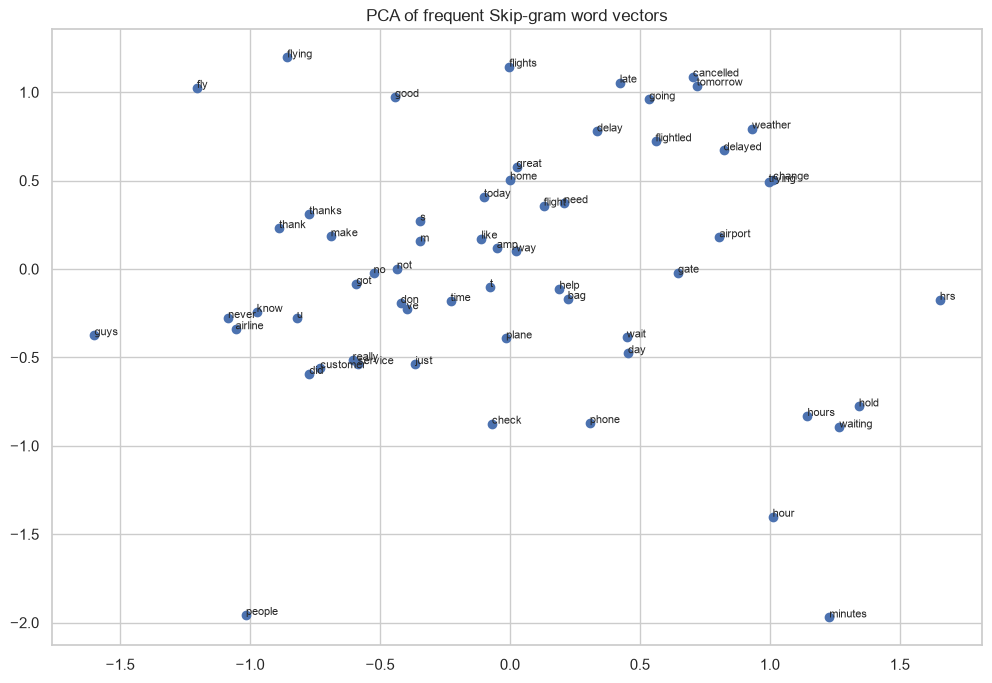

In [23]:
skip = w2v_models["Skip-gram"]
frequent = [w for w,c in Counter(w for row in train_tokens for w in row).most_common(60) if w in skip.wv]
if len(frequent) >= 2:
    coords = PCA(n_components=2, random_state=42).fit_transform(np.array([skip.wv[w] for w in frequent]))
    plt.figure(figsize=(12,8))
    plt.scatter(coords[:,0],coords[:,1])
    for i,w in enumerate(frequent): plt.annotate(w,(coords[i,0],coords[i,1]),fontsize=8)
    plt.title("PCA of frequent Skip-gram word vectors"); plt.savefig("outputs/plot_31.png", dpi=150, bbox_inches="tight")
plt.savefig("outputs/plot_31_1.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation — PCA embedding plot
PCA compresses the Skip-gram word vectors into two dimensions. Words appearing near one another have more similar learned contexts in the training tweets, but this view is only an approximation of the original 100-dimensional space. The corpus is relatively small, so some neighbours and clusters may be noisy.

In [24]:
def doc_vector(tokens, model):
    vectors = [model.wv[w] for w in tokens if w in model.wv]
    return np.mean(vectors,axis=0) if vectors else np.zeros(model.vector_size)

chosen_w2v = w2v_models["Skip-gram"]
X_train_w2v = np.vstack([doc_vector(tokenize(t),chosen_w2v) for t in X_train])
X_test_w2v = np.vstack([doc_vector(tokenize(t),chosen_w2v) for t in X_test])
print("Word2Vec document feature shapes:",X_train_w2v.shape,X_test_w2v.shape)

Word2Vec document feature shapes: (11683, 100) (2921, 100)


## Task 6 — Text classification and model comparison

Text classification assigns one label to a complete document. The pipeline is raw text → cleaning → feature representation → classifier → prediction → evaluation. A scikit-learn Pipeline keeps vectoriser fitting tied to training folds and makes the vectoriser-plus-classifier easy to save and deploy. `class_weight='balanced'` compensates for the imbalanced class frequencies.

Accuracy: 0.7918521054433413
Macro-F1: 0.7401559616316415
              precision    recall  f1-score   support

    negative       0.88      0.85      0.87      1832
     neutral       0.60      0.67      0.63       618
    positive       0.73      0.71      0.72       471

    accuracy                           0.79      2921
   macro avg       0.74      0.74      0.74      2921
weighted avg       0.80      0.79      0.79      2921



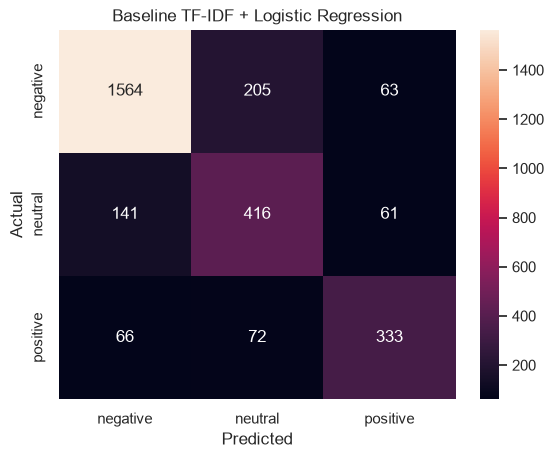

In [25]:
baseline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1,2), min_df=2)),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))
])
baseline.fit(X_train,y_train)
base_pred = baseline.predict(X_test)
print("Accuracy:",accuracy_score(y_test,base_pred))
print("Macro-F1:",f1_score(y_test,base_pred,average="macro"))
print(classification_report(y_test,base_pred,zero_division=0))
sns.heatmap(confusion_matrix(y_test,base_pred,labels=["negative","neutral","positive"]),
            annot=True,fmt="d",xticklabels=["negative","neutral","positive"],
            yticklabels=["negative","neutral","positive"])
plt.title("Baseline TF-IDF + Logistic Regression"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.savefig("outputs/plot_35.png", dpi=150, bbox_inches="tight")
plt.savefig("outputs/plot_35_1.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation — Confusion matrix
The model correctly classifies many negative tweets, but neutral tweets are more often confused with negative than positive. The diagonal cells are correct predictions; off-diagonal cells are errors. This supports using macro-F1 and per-class recall, rather than relying on accuracy alone.

In [26]:
models = {
    "BoW + MultinomialNB": Pipeline([("vec",CountVectorizer(min_df=2)),("clf",MultinomialNB())]),
    "BoW + LogisticRegression": Pipeline([("vec",CountVectorizer(min_df=2)),("clf",LogisticRegression(max_iter=1000,class_weight="balanced"))]),
    "TF-IDF unigram + LogisticRegression": Pipeline([("vec",TfidfVectorizer(ngram_range=(1,1),min_df=2)),("clf",LogisticRegression(max_iter=1000,class_weight="balanced"))]),
    "TF-IDF uni+bi + LogisticRegression": baseline,
    "TF-IDF uni+bi + MultinomialNB": Pipeline([("vec",TfidfVectorizer(ngram_range=(1,2),min_df=2)),("clf",MultinomialNB())])
}
comparison = []
fitted_models = {}
for name, model in models.items():
    start=time.time()
    model.fit(X_train,y_train)
    pred=model.predict(X_test)
    comparison.append({"Features / Classifier":name,"Accuracy":accuracy_score(y_test,pred),
                       "Macro-F1":f1_score(y_test,pred,average="macro"),
                       "Training time (s)":round(time.time()-start,2)})
    fitted_models[name]=model
# Add heuristic and VADER rows from Task 3.
for row in results_basic:
    comparison.append({"Features / Classifier":row["Approach"],"Accuracy":row["Accuracy"],
                       "Macro-F1":row["Macro-F1"],"Training time (s)":0})
results_df=pd.DataFrame(comparison).sort_values("Macro-F1",ascending=False)
display(results_df)

,Features / Classifier,Accuracy,Macro-F1,Training time (s)
3,TF-IDF uni+bi + LogisticRegression,0.791852,0.740156,5.05
2,TF-IDF unigram + LogisticRegression,0.767888,0.721069,1.68
1,BoW + LogisticRegression,0.768230,0.720294,1.79
0,BoW + MultinomialNB,0.775419,0.695829,1.79
5,Heuristic,0.509415,0.531572,0.00
6,VADER,0.539541,0.508932,0.00
4,TF-IDF uni+bi + MultinomialNB,0.697022,0.486430,2.42


In [27]:
best_name = results_df.iloc[0]["Features / Classifier"]
best_pipeline = fitted_models.get(best_name, baseline)
print("Best ML pipeline:", best_name)
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
cv_scores = cross_val_score(best_pipeline, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
print("5-fold macro-F1 mean:",cv_scores.mean(),"std:",cv_scores.std())

Best ML pipeline: TF-IDF uni+bi + LogisticRegression
5-fold macro-F1 mean: 0.7400153092094792 std: 0.011873946663698075


In [28]:
best_pred = best_pipeline.predict(X_test)
errors = pd.DataFrame({"text":X_test,"true":y_test,"predicted":best_pred})
errors = errors[errors.true != errors.predicted].head(8)
display(errors)

,text,true,predicted
10909,call gate d in clt and get me on this flight,neutral,negative
3687,have reported it still in istanbul at the mome...,positive,negative
453,that s classy,positive,neutral
730,thanks for the lack of help and the canned res...,negative,positive
11817,i booked a flight yesterday but didnt receive ...,negative,neutral
2654,will the airline refuse my canadian passport w...,neutral,negative
8036,heading to buffalo trading the cold in boston ...,positive,negative
7512,i know but i wanted to pass it along not good ...,negative,positive


In [29]:
# Save a self-contained vectorizer + classifier pipeline. Cleaning is applied before prediction in app.py.
joblib.dump(best_pipeline,"sentiment_model.joblib")
reloaded = joblib.load("sentiment_model.joblib")
print("Reloaded predictions:",reloaded.predict([
    clean_text("Thank you, the crew was wonderful!"),
    clean_text("My flight was delayed and the service was awful."),
    clean_text("My flight is scheduled for 8 PM.")
]))
import sklearn
print("scikit-learn version:",sklearn.__version__)

Reloaded predictions: ['positive' 'negative' 'negative']
scikit-learn version: 1.9.1


## Task 7 — Part-of-speech (POS) tagging

POS tagging assigns grammatical labels using context. Common Penn Treebank tags include NN (noun), VB (verb), JJ (adjective), RB (adverb), PRP (pronoun) and IN (preposition). NLTK's `pos_tag` uses a trained statistical tagger; tweets can be difficult because of abbreviations, missing punctuation and informal grammar.

In [30]:
nltk.download("averaged_perceptron_tagger_eng",quiet=True)
nltk.download("averaged_perceptron_tagger",quiet=True)
ambiguity = ["I will park the car near the airport.", "The park is close to the airport."]
for sentence in ambiguity:
    print(sentence, nltk.pos_tag(nltk.word_tokenize(sentence)))
for tweet in df["clean_text"].head(5):
    print(tweet, nltk.pos_tag(nltk.word_tokenize(tweet)))

I will park the car near the airport. [('I', 'PRP'), ('will', 'MD'), ('park', 'VB'), ('the', 'DT'), ('car', 'NN'), ('near', 'IN'), ('the', 'DT'), ('airport', 'NN'), ('.', '.')]
The park is close to the airport. [('The', 'DT'), ('park', 'NN'), ('is', 'VBZ'), ('close', 'RB'), ('to', 'TO'), ('the', 'DT'), ('airport', 'NN'), ('.', '.')]
what said [('what', 'WP'), ('said', 'VBD')]
plus you ve added commercials to the experience tacky [('plus', 'CC'), ('you', 'PRP'), ('ve', 'VBP'), ('added', 'JJ'), ('commercials', 'NNS'), ('to', 'TO'), ('the', 'DT'), ('experience', 'NN'), ('tacky', 'NN')]
i didn t today must mean i need to take another trip [('i', 'NN'), ('didn', 'VBP'), ('t', 'NN'), ('today', 'NN'), ('must', 'MD'), ('mean', 'VB'), ('i', 'NNS'), ('need', 'VBP'), ('to', 'TO'), ('take', 'VB'), ('another', 'DT'), ('trip', 'NN')]
it s really aggressive to blast obnoxious entertainment in your guests faces amp they have little recourse [('it', 'PRP'), ('s', 'VBZ'), ('really', 'RB'), ('aggressive'

,JJ,RB,VB,NN
sentiment,,,,
negative,1.537520,1.137031,4.065253,5.175367
neutral,1.068807,0.616972,2.809633,4.041284
positive,1.284024,0.819527,2.464497,3.778107


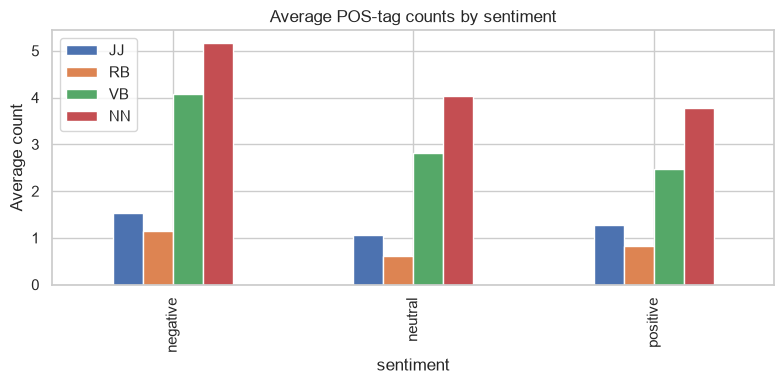

In [31]:
# Sample up to 2,000 training tweets for POS distribution.
sample_idx = X_train.index[:min(2000,len(X_train))]
pos_counts = []
for idx in sample_idx:
    sent = df.loc[idx,"clean_text"]
    tags = nltk.pos_tag(nltk.word_tokenize(sent))
    counts = Counter(tag[:2] for _,tag in tags)
    row = {"sentiment":df.loc[idx,"airline_sentiment"]}
    for tag in ["JJ","RB","VB","NN"]:
        row[tag] = counts[tag]
    pos_counts.append(row)
pos_df=pd.DataFrame(pos_counts)
display(pos_df.groupby("sentiment")[["JJ","RB","VB","NN"]].mean())
pos_df.groupby("sentiment")[["JJ","RB","VB","NN"]].mean().plot(kind="bar",figsize=(8,4))
plt.title("Average POS-tag counts by sentiment"); plt.ylabel("Average count"); plt.tight_layout(); plt.savefig("outputs/plot_43.png", dpi=150, bbox_inches="tight")
plt.savefig("outputs/plot_43_1.png", dpi=150, bbox_inches="tight")
plt.show()

### Interpretation — POS distribution
This chart is generated when the NLTK averaged-perceptron POS tagger resource is available. Compare adjective, adverb, verb and noun proportions across sentiment classes. POS patterns are descriptive rather than proof of sentiment, and informal tweet grammar can lead to tagging errors. If the tagger data is unavailable offline, download the resource once and rerun Task 7.

## Task 8 — Streamlit app and deployment

The app is provided in `app.py` and shares the same `clean_text()` and heuristic functions through `nlp_utils.py`. Run Task 6.7 first so `sentiment_model.joblib` exists.

### Run locally
```bash
pip install -r requirements.txt
streamlit run app.py
```

---


## What I Learned

### 1. Which pipeline stage had the biggest effect on accuracy?

Feature extraction had a significant impact on model performance. TF-IDF with unigrams and bigrams achieved a macro-F1 score of 0.7402, compared to 0.7211 with unigrams alone. Bigrams helped the model understand short phrases and word combinations, improving sentiment classification.

### 2. Which approach did I deploy and why?

I selected the Machine Learning approach using TF-IDF (unigrams + bigrams) and Logistic Regression. It achieved the best macro-F1 score of 0.7402 and an accuracy of 79.19% among the tested approaches. It performed better than the Heuristic and VADER approaches.

### 3. What is one weakness of my app?

The application may struggle to correctly identify sarcasm, irony and context-dependent expressions. For example, a tweet saying "Great service, another delayed flight!" may be interpreted incorrectly because the model does not fully understand sarcasm.

### 4. What is one possible future improvement?

A possible future improvement is implementing BERT (Bidirectional Encoder Representations from Transformers) to better understand context and relationships between words. However, it is outside the scope of this practical.

---